In [51]:
#Import filter warning module
import warnings
warnings.filterwarnings(action = 'ignore')

In [52]:
import pandas as pd

# prepare 1D Data series

one_dseries =pd.Series([1,2,3])
one_dseries


,0
0,1
1,2
2,3


In [53]:
data1 =pd.Series({'India':100,'USA':200})
data1

,0
India,100
USA,200


In [54]:
data2 = pd.DataFrame({
    'SrNo':[1,2,3,4,5,6,7,8,9,10],
    'Name':['A','B','C','D','E','F','G','H','I','J'],
    'Marks':[10,20,30,40,50,60,70,80,90,100],
    'CGPA':[9,8,7,6,5,4,3,2,1,9]
})
data2

,SrNo,Name,Marks,CGPA
0,1,A,10,9
1,2,B,20,8
2,3,C,30,7
3,4,D,40,6
4,5,E,50,5
5,6,F,60,4
6,7,G,70,3
7,8,H,80,2
8,9,I,90,1
9,10,J,100,9


In [55]:
#checking dataset information
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   SrNo    10 non-null     int64 
 1   Name    10 non-null     object
 2   Marks   10 non-null     int64 
 3   CGPA    10 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 452.0+ bytes


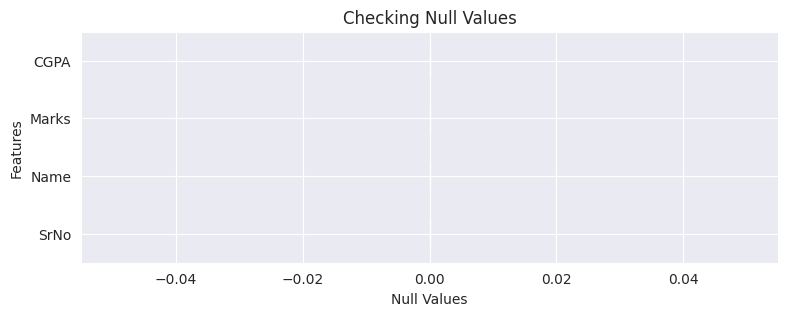

In [56]:
#checking null values information
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

plt.figure(figsize=(9,3))
data2.isnull().sum().plot(kind='barh')
plt.title('Checking Null Values')
plt.xlabel('Null Values')
plt.ylabel('Features')
plt.show()


In [57]:
#checking duplicate values
data2.duplicated()   # helps use to check duplicate records present in dataset
data2.drop_duplicates() # this will drop the dupicated record from the dataset


,SrNo,Name,Marks,CGPA
0,1,A,10,9
1,2,B,20,8
2,3,C,30,7
3,4,D,40,6
4,5,E,50,5
5,6,F,60,4
6,7,G,70,3
7,8,H,80,2
8,9,I,90,1
9,10,J,100,9


In [58]:
#checking descriptive stats for numerical data
data2.describe(exclude='object')

,SrNo,Marks,CGPA
count,10.00000,10.000000,10.000000
mean,5.50000,55.000000,5.400000
std,3.02765,30.276504,2.875181
min,1.00000,10.000000,1.000000
25%,3.25000,32.500000,3.250000
50%,5.50000,55.000000,5.500000
75%,7.75000,77.500000,7.750000
max,10.00000,100.000000,9.000000


In [59]:
#checking descriptive stats for categorical data
data2.describe(include='object')

,Name
count,10
unique,10
top,A
freq,1


In [60]:
from numpy import quantile
#checking descriptive stats using column orderedict function
#step1: segregate categorical data and numerical data

numerical_col =data2.select_dtypes(exclude='object').columns
categorical_col = data2.select_dtypes(include='object').columns

stats=[]
from collections import OrderedDict
for i in numerical_col:
  numerical_stats = OrderedDict({
      'Feature':i,
      'count':data2[i].count(),
      '% of Missing value':(data2[i].isnull().sum()/len(data2)) * 100,
      'Maximum':data2[i].max(),
      'Minmum':data2[i].min(),
      'Mean':data2[i].mean(),
      'Median':data2[i].median(),
      'Q1':data2[i].quantile(0.25),
      'Q3':data2[i].quantile(0.75),
      'IQR':data2[i].quantile(0.75)-data2[i].quantile(0.25),
      'Standard Deviation':data2[i].std(),
      'Variance':data2[i].var(),
      'skewness':data2[i].skew(),
      'kurtosis':data2[i].kurtosis()
  })
  stats.append(numerical_stats)
  report = pd.DataFrame(stats)

report

,Feature,count,% of Missing value,Maximum,Minmum,Mean,Median,Q1,Q3,IQR,Standard Deviation,Variance,skewness,kurtosis
0,SrNo,10,0.0,10,1,5.5,5.5,3.25,7.75,4.5,3.027650,9.166667,0.000000,-1.200000
1,Marks,10,0.0,100,10,55.0,55.0,32.50,77.50,45.0,30.276504,916.666667,0.000000,-1.200000
2,CGPA,10,0.0,9,1,5.4,5.5,3.25,7.75,4.5,2.875181,8.266667,-0.151463,-1.356985


In [61]:
#saving report file as CSV
report.to_csv('report.csv')

<Axes: >

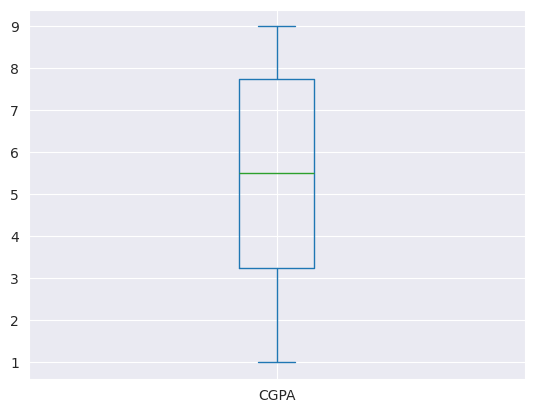

In [62]:
data2['CGPA'].plot(kind='box')

<Axes: ylabel='Density'>

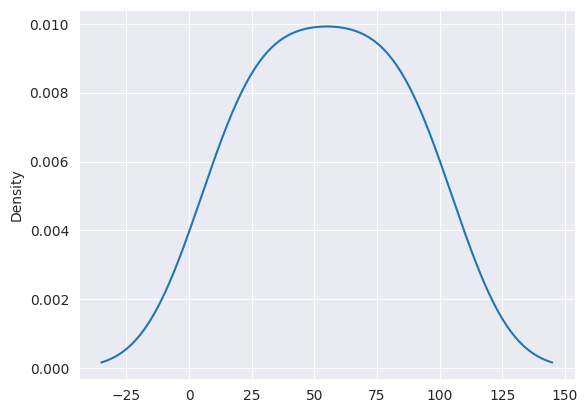

In [63]:
data2['Marks'].plot(kind='kde')

In [64]:
import pandas as pd
import numpy as np

In [65]:

df = pd.DataFrame({
    'SrNo':[1,2,3,4,5,6,7,8,9,10],
    'Name':['A','B','C','D','E','F','G','H','I','J'],
    'Department':[np.nan,np.nan,'IT','HR','Finance','IT','HR','Finance','IT','HR'],
    'Salary':[np.nan,2000,3000,6000,8000,np.nan,7600,8900,10000,3000],
    'YrExp':[1,2,3,4,5,6,7,8,9,10]
})
df

,SrNo,Name,Department,Salary,YrExp
0,1,A,NaN,NaN,1
1,2,B,NaN,2000.0,2
2,3,C,IT,3000.0,3
3,4,D,HR,6000.0,4
4,5,E,Finance,8000.0,5
5,6,F,IT,NaN,6
6,7,G,HR,7600.0,7
7,8,H,Finance,8900.0,8
8,9,I,IT,10000.0,9
9,10,J,HR,3000.0,10


In [66]:
#prepare a dummy copy of datafrme
df1 = df.copy()
df1

,SrNo,Name,Department,Salary,YrExp
0,1,A,NaN,NaN,1
1,2,B,NaN,2000.0,2
2,3,C,IT,3000.0,3
3,4,D,HR,6000.0,4
4,5,E,Finance,8000.0,5
5,6,F,IT,NaN,6
6,7,G,HR,7600.0,7
7,8,H,Finance,8900.0,8
8,9,I,IT,10000.0,9
9,10,J,HR,3000.0,10


In [67]:
# drop unwanted column from dataset
# df1.drop(columns=['SrNo']) # this will temporarily delete the column
df1.drop(columns=['SrNo'],inplace=True) # this will delete the column permanently
df1


,Name,Department,Salary,YrExp
0,A,NaN,NaN,1
1,B,NaN,2000.0,2
2,C,IT,3000.0,3
3,D,HR,6000.0,4
4,E,Finance,8000.0,5
5,F,IT,NaN,6
6,G,HR,7600.0,7
7,H,Finance,8900.0,8
8,I,IT,10000.0,9
9,J,HR,3000.0,10


In [68]:
#checking unique values present in dataset column
df1['Department'].unique()

array([nan, 'IT', 'HR', 'Finance'], dtype=object)

In [69]:
#checking number of  unique values present in dataset
df1['Department'].nunique()

3

In [70]:
#checking values counts present in dataset column
df1['Department'].value_counts()

,count
Department,
IT,3
HR,3
Finance,2


<Axes: ylabel='count'>

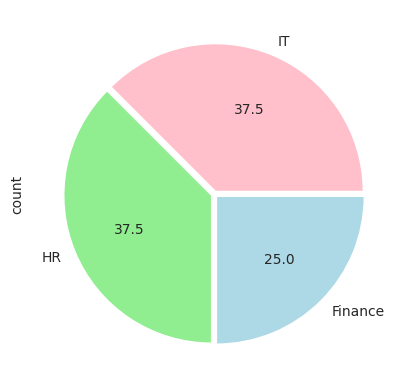

In [71]:
#checking values counts present in dataset column:usig graphical approch
df1['Department'].value_counts().plot(kind='pie',
                                      autopct ='%1.1f',
                                      explode = [0.02,0.02,0.02],
                                      colors =['pink','lightgreen','lightblue'])

In [72]:
#Imputation stratergies
'''
1. Imputation with numerical columns :
 - In such case imputation is usually done with  'median'.
 - Before imputation , please ensure that % of missing value presenr in dataset
 column

2. Imputation with categorical columns :
 - In such case imputation is usually done with  'mode'.
 - Before imputation , please ensure that % of missing value presenr in dataset
 column

3. Imputation can be done in four ways
 - mean : average value
 - median : central value
 - mode : most frequent occuring value
 - any arbitary constant value

4.In Machine Learning production cycle , the impulation can be done using
follwing methods
 - fillna()
 -SimpleImputer () #this is a module of scikit-learn
 -KnnImputer() # this is a module of scikit-learn

 note :
 - 10% of the missing value can be imputed
 - if the dataset contains more than 10% of the missing value then better drop
 the column
 - if the dataset contains more than 15% of the missing value then some cases
 you can use bucketing technique .[Bins Technique]


'''

"\n1. Imputation with numerical columns :\n - In such case imputation is usually done with  'median'.\n - Before imputation , please ensure that % of missing value presenr in dataset\n column\n\n2. Imputation with categorical columns :\n - In such case imputation is usually done with  'mode'.\n - Before imputation , please ensure that % of missing value presenr in dataset\n column\n\n3. Imputation can be done in four ways\n - mean : average value\n - median : central value\n - mode : most frequent occuring value\n - any arbitary constant value\n\n4.In Machine Learning production cycle , the impulation can be done using\nfollwing methods\n - fillna()\n -SimpleImputer () #this is a module of scikit-learn\n -KnnImputer() # this is a module of scikit-learn\n\n note :\n - 10% of the missing value can be imputed\n - if the dataset contains more than 10% of the missing value then better drop\n the column\n - if the dataset contains more than 15% of the missing value then some cases\n you can 

In [73]:
#imputation of fillna()
df1 ['Department'].fillna(df1['Department'].mode()[0],
                          inplace=True)

In [74]:
#Imputation using any arbitrary constant value
df1['Salary'].fillna(1099,
                     inplace=True)

In [75]:
df1

,Name,Department,Salary,YrExp
0,A,HR,1099.0,1
1,B,HR,2000.0,2
2,C,IT,3000.0,3
3,D,HR,6000.0,4
4,E,Finance,8000.0,5
5,F,IT,1099.0,6
6,G,HR,7600.0,7
7,H,Finance,8900.0,8
8,I,IT,10000.0,9
9,J,HR,3000.0,10


In [76]:
df1[df1['Department']=='IT']


,Name,Department,Salary,YrExp
2,C,IT,3000.0,3
5,F,IT,1099.0,6
8,I,IT,10000.0,9


In [77]:
df1[df1['Department']=='HR']

,Name,Department,Salary,YrExp
0,A,HR,1099.0,1
1,B,HR,2000.0,2
3,D,HR,6000.0,4
6,G,HR,7600.0,7
9,J,HR,3000.0,10


In [78]:
df1[(df1['Department']=='IT') & (df1['Salary'] >=7000)]

,Name,Department,Salary,YrExp
8,I,IT,10000.0,9


In [79]:
#calculate total sum of salary having department is IT and YrExp greater than 3
df1[(df1['Department']=='IT') &(df1['YrExp']>3)]['Salary'].sum()

np.float64(11099.0)

In [80]:
#preapre dataset for EDA
df2=pd.DataFrame({
    'SrNo':[1,2,3,4,5,6,7,8,9,10],
    'Train Name':['A','B','C','D','E','F','G','H','I','J'],
    'Booking':[1,0,1,1,1,0,0,0,1,0],
    'Gender':['M','F','M','F','M','F','M','F','F','F'],
    'Age':[21,22,23,24,25,26,27,28,29,30],
    'Fare':[100,200,300,400,500,600,700,800,900,1000]


})




<Axes: ylabel='Gender'>

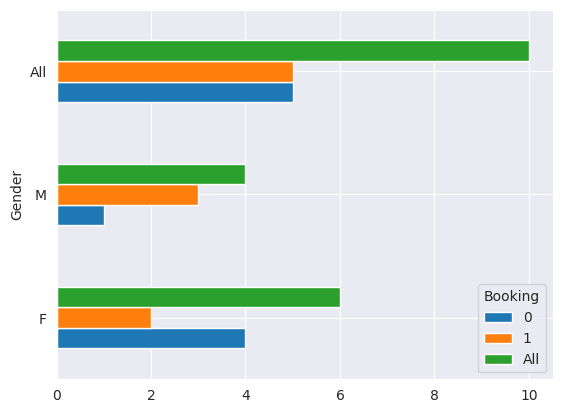

In [81]:
pd.crosstab(index=(df2['Gender']),
            columns=(df2['Booking']),
            margins= True).plot(kind='barh')

In [82]:
pd.crosstab(index=[df2['Gender'],df2['Age']],
            columns=[df2['Booking']],
            margins= True).T

Gender   F                 M          All
Age     22 24 26 28 29 30 21 23 25 27    
Booking                                  
0        1  0  1  1  0  1  0  0  0  1   5
1        0  1  0  0  1  0  1  1  1  0   5
All      1  1  1  1  1  1  1  1  1  1  10

## **Titanic Case Study**

In [83]:
#import necessary Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import logging
logging.basicConfig(level = logging.INFO,
                    filename = 'TitanicCaseStudy',
                    filemode = 'w',
                    format ='%(asctime)s - %(message)s - %(levelname)s',
                    force = True )
import warnings
warnings.filterwarnings(action = 'ignore')




In [87]:
# Step1 : Data Ingestion
filepath ='/content/Titanic-Dataset.csv'
try:
  df = pd.read_csv(filepath)
except FileNotFoundError:
  logging.exception('File Not Found Please Check FilePath')

df.head()




,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [90]:
# Step2 : Data Preprocessing
'''
1.check dataset information
2. check the null values
3. check the duplicated values and drop duplicate values
4. check descriptive stats : categorical and for numerical
5. check imputation stratergies
6. data preprocessing and Feature engineering

'''

# ----------------------------------------------------
# check DataSet Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


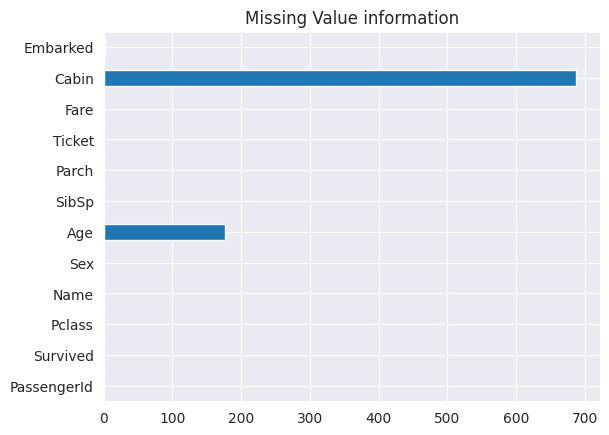

In [92]:
#---------------------------------------
# checking Null Values Present in the Dataset
df.isnull().sum().plot(kind = 'barh')
plt.title("Missing Value information")
plt.show()

In [93]:
#-----------------------------------------------
# Drop Duplicates records Present in dataset
data = df.copy()  # prepare a copy of data frame
data.drop_duplicates(inplace = True)


In [105]:
# Descriptive Stats: Numerical and Categorical Columns
# -----------------------------------------------
# segregate Numerical columns and Categorical column
numerical_col = data.select_dtypes(exclude='object').columns
categorical_col = data.select_dtypes(include='object').columns
# -----------------------------------------------
from collections import OrderedDict
stats = []
for i in numerical_col:
  numerical_stats = OrderedDict({
      'Feature':i,
      'Count':data[i].count(),
      '% of Missing value':data[i].isnull().sum()/len(data)*100,
      'Maximum':data[i].max(),
      'Minimum':data[i].min(),
      'Mean':data[i].mean(),
      'Median':data[i].median(),
      'Q1':data[i].quantile(0.25),
      'Q3':data[i].quantile(0.75),
      'IQR':data[i].quantile(0.75)-data[i].quantile(0.25),
      'Standard Deviation':data[i].std(),
      'Skewness':data[i].skew(),
      'Kurtosis':data[i].kurtosis()
  })
  stats.append(numerical_stats)
  numerical_stats_report = pd.DataFrame(stats)
numerical_stats_report




,Feature,Count,% of Missing value,Maximum,Minimum,Mean,Median,Q1,Q3,IQR,Standard Deviation,Skewness,Kurtosis
0,PassengerId,891,0.00000,891.0000,1.00,446.000000,446.0000,223.5000,668.5,445.0000,257.353842,0.000000,-1.200000
1,Survived,891,0.00000,1.0000,0.00,0.383838,0.0000,0.0000,1.0,1.0000,0.486592,0.478523,-1.775005
2,Pclass,891,0.00000,3.0000,1.00,2.308642,3.0000,2.0000,3.0,1.0000,0.836071,-0.630548,-1.280015
3,Age,714,19.86532,80.0000,0.42,29.699118,28.0000,20.1250,38.0,17.8750,14.526497,0.389108,0.178274
4,SibSp,891,0.00000,8.0000,0.00,0.523008,0.0000,0.0000,1.0,1.0000,1.102743,3.695352,17.880420
5,Parch,891,0.00000,6.0000,0.00,0.381594,0.0000,0.0000,0.0,0.0000,0.806057,2.749117,9.778125
6,Fare,891,0.00000,512.3292,0.00,32.204208,14.4542,7.9104,31.0,23.0896,49.693429,4.787317,33.398141


In [109]:
stats1 =[]
for i in categorical_col:
  categorical_stats = OrderedDict({
      'Feature':i,
      'Count':data[i].count(),
      '% of Missing value':data[i].isnull().sum()/len(data)*100,
      'Mode':data[i].mode()[0],
      'unique values':data[i].nunique(),
      'value counts':data[i].value_counts()

  })
  stats1.append(categorical_stats)
  categorical_stats_report = pd.DataFrame(stats1)
categorical_stats_report



,Feature,Count,% of Missing value,Mode,unique values,value counts
0,Name,891,0.000000,"Abbing, Mr. Anthony",891,"Name Dooley, Mr. Patrick ..."
1,Sex,891,0.000000,male,2,"Sex male 577 female 314 Name: count, d..."
2,Ticket,891,0.000000,1601,681,Ticket 347082 7 1601 ...
3,Cabin,204,77.104377,B96 B98,147,Cabin G6 4 C23 C25 C27 4 B96 B9...
4,Embarked,889,0.224467,S,3,Embarked S 644 C 168 Q 77 Name: coun...


In [89]:
# Step3 : EDA : Explpratory Data Analysis

## **Observation Based on Case Study**
* The Given Dataset Contains 12 columns and891 rows . Out of these Age and Cabin are having more than 15% of missing values .

* Two Columns : SibSp and Fare shows highly non normal distribution a fare decision can be taken to drop these columns